# WikiDT Image EDA — Persistent Google Drive Dataset

**Run from the top in a new Google Colab runtime.** The notebook checks Google Drive before downloading anything. It saves full-page PNGs, subpage PNGs, table detection XML annotations, and QA train/val/test JSON. Original EDA and random visualizations are retained.

**Storage warning:** The extracted image collection is large, and accessing tens of thousands of individual files directly from mounted Drive may be slow. Ensure adequate Google Drive quota. Files are saved under `MyDrive/WikiDT_Persistent/`. The first run may take a long time. Colab's `/content` cache is temporary; Google Drive persists.

**Scope:** This notebook saves the *detection* train/val/test XML and TableVQA JSON splits, **not** the separate `structure/` table-crop dataset. Table crops can be generated from detection bounding boxes for initial experiments.

In [1]:
!pip -q install -U huggingface_hub pandas pillow matplotlib tqdm

from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
from huggingface_hub import HfApi, hf_hub_download
from tqdm.auto import tqdm
from PIL import Image
from IPython.display import display
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import shutil, subprocess, json, re, os

REPO_ID = "AmazonScience/WikiDT"
DRIVE_ROOT = Path('/content/drive/MyDrive/WikiDT_Persistent')
DATA_DIR = DRIVE_ROOT / 'data'
RESULTS_DIR = DRIVE_ROOT / 'results'
MARKER_DIR = DRIVE_ROOT / '.completed'
for p in [DATA_DIR, RESULTS_DIR, MARKER_DIR]:
    p.mkdir(parents=True, exist_ok=True)

api = HfApi()
print('Persistent data:', DATA_DIR)
print('EDA results:', RESULTS_DIR)
print('Colab free GB:', round(shutil.disk_usage('/content').free/1024**3,1))

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.0 which is incompatible.
gradio 6.31.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
datasets 4.8.5 requires huggingface-hub<2.0,>=0.25.0, but you have huggingface-hub 2.4.0 which is incompatible.
Mounted at /content/drive


/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


Persistent data: /content/drive/MyDrive/WikiDT_Persistent/data
EDA results: /content/drive/MyDrive/WikiDT_Persistent/results
Colab free GB: 225.6


## 1. Inspect persistent data first

These checks do not contact Hugging Face. A `.complete` marker is written only after the extraction has passed count checks. If a previous extraction was interrupted, the notebook will retry safely using a staging directory.

In [2]:
FULL_IMAGE_DIR = DATA_DIR / 'images'
SUB_IMAGE_DIR = DATA_DIR / 'detection' / 'images'
DETECTION_DIR = DATA_DIR / 'detection'
EXPECTED_FULL = 16887
EXPECTED_SUB = 54032

def png_count(folder, pattern='*.png'):
    return sum(1 for _ in folder.rglob(pattern)) if folder.exists() else 0

def status():
    print('Full images:', png_count(FULL_IMAGE_DIR), '/', EXPECTED_FULL)
    print('Subpages:', png_count(SUB_IMAGE_DIR), '/', EXPECTED_SUB)
    for split in ('train','val','test'):
        xml_dir = DETECTION_DIR / split
        print(f'Detection {split} XML:', sum(1 for _ in xml_dir.rglob('*.xml')) if xml_dir.exists() else 0)
    print('Completion markers:', [p.name for p in MARKER_DIR.glob('*.complete')])
status()

Full images: 16887 / 16887
Subpages: 0 / 54032
Detection train XML: 43248
Detection val XML: 5374
Detection test XML: 5410
Completion markers: ['full.complete', 'detection.complete']


## 2. Download only missing image archives, extract once to Drive

The nine `images.part*` files are *pieces of one TAR archive*. Likewise `detection.part*` is another TAR archive. This notebook never treats the parts as independent folders. Archive pieces are downloaded into the temporary Hugging Face cache, concatenated as a stream, and extracted to a staging directory in Drive. On successful verification, the extracted dataset is moved into place.

If the extracted data is already present but the marker is missing (for example, copied from an earlier notebook), the code validates it and marks it complete without downloading. It does **not** delete existing data.

In [5]:
def archive_ready(kind):
    if kind == 'full':
        return png_count(FULL_IMAGE_DIR, '*_page.png') == EXPECTED_FULL
    if kind == 'detection':
        return (png_count(SUB_IMAGE_DIR) == EXPECTED_SUB
                and all((DETECTION_DIR / s).exists() and
                        any((DETECTION_DIR / s).rglob('*.xml'))
                        for s in ('train','val','test')))
    raise ValueError(kind)

for kind in ('full','detection'):
    if archive_ready(kind):
        (MARKER_DIR / f'{kind}.complete').write_text('Verified by count and annotation checks\n')

need_archives = [kind for kind in ('full','detection') if not archive_ready(kind)]
print('Archives needing download/extraction:', need_archives or 'NONE')

if need_archives:
    repo_files = api.list_repo_files(repo_id=REPO_ID, repo_type='dataset')
else:
    repo_files = []

image_parts = sorted(f for f in repo_files if f.startswith('WikiDT-dataset/images.part'))
detection_parts = sorted(f for f in repo_files if f.startswith('WikiDT-dataset/WikiTableExtraction/detection.part'))
print('Missing archive part groups:', {k:len(v) for k,v in [('full',image_parts),('detection',detection_parts)]})

Archives needing download/extraction: NONE
Missing archive part groups: {'full': 0, 'detection': 0}


In [6]:
def extract_split_archive(kind, filenames):
    if archive_ready(kind):
        print(f'{kind}: already available on Drive; skipping download')
        return
    if not filenames:
        raise RuntimeError(f'No archive parts discovered for {kind}')
    stage = DATA_DIR / f'.staging_{kind}'
    if stage.exists():
        print('Removing incomplete staging folder:', stage)
        shutil.rmtree(stage)
    stage.mkdir(parents=True)
    paths = [Path(hf_hub_download(repo_id=REPO_ID, filename=f, repo_type='dataset'))
             for f in tqdm(filenames, desc=f'Download {kind} archive')]
    cat = subprocess.Popen(['cat', *map(str, paths)], stdout=subprocess.PIPE)
    try:
        tar = subprocess.run(['tar','-xf','-','-C',str(stage)],
                             stdin=cat.stdout, capture_output=True, text=True)
    finally:
        cat.stdout.close()
    cat.wait()
    if cat.returncode or tar.returncode:
        raise RuntimeError(f'{kind} extraction failed: {tar.stderr[-2000:]}')

    if kind == 'full':
        target = FULL_IMAGE_DIR
        # Handle either images/ or WikiDT-dataset/images/ archive paths
        candidates = [p for p in stage.rglob('images') if p.is_dir() and
                      sum(1 for _ in p.glob('*_page.png')) == EXPECTED_FULL]
    else:
        target = DETECTION_DIR
        candidates = [p for p in stage.rglob('detection') if p.is_dir() and
                      png_count(p / 'images') == EXPECTED_SUB and
                      all(any((p/s).rglob('*.xml')) for s in ('train','val','test'))]
    if len(candidates) != 1:
        raise RuntimeError(f'{kind}: expected one valid extracted folder, found {len(candidates)}; staging retained for inspection: {stage}')
    if target.exists():
        # Existing incomplete directory is retained instead of silently deleting user data.
        raise RuntimeError(f'{target} exists but is incomplete. Inspect it and {stage} before replacing.')
    candidates[0].rename(target)
    if not archive_ready(kind):
        raise RuntimeError(f'{kind}: post-move validation failed')
    (MARKER_DIR / f'{kind}.complete').write_text('Verified complete\n')
    shutil.rmtree(stage)
    print(f'{kind}: saved permanently at {target}')

# These two calls skip completely on subsequent notebook runs.
extract_split_archive('full', image_parts)
extract_split_archive('detection', detection_parts)
status()

full: already available on Drive; skipping download
detection: already available on Drive; skipping download
Full images: 16887 / 16887
Subpages: 54032 / 54032
Detection train XML: 43248
Detection val XML: 5374
Detection test XML: 5410
Completion markers: ['full.complete', 'detection.complete']


## Optional: free temporary Hugging Face cache disk space

Only run after verifying the Drive files. This deletes the **temporary Colab cache for WikiDT**, not the persistent Drive dataset. It is optional and may force a re-download if Drive extraction was incomplete.


In [4]:
# OPTIONAL — leave commented until Drive copies are verified.
# from pathlib import Path
# import shutil
# assert archive_ready('full') and archive_ready('detection')
# cache_dir = Path('/root/.cache/huggingface/hub/datasets--AmazonScience--WikiDT')
# if cache_dir.exists():
#     shutil.rmtree(cache_dir)
#     print('Temporary WikiDT cache cleared. Drive dataset is unchanged.')

## 4. Rebuild EDA DataFrames from Google Drive

All paths in subsequent cells refer to persistent Drive files. No Hugging Face download is needed for EDA after the initial setup.

In [8]:
full_images = sorted(FULL_IMAGE_DIR.glob('*_page.png'))
sub_images = sorted(SUB_IMAGE_DIR.rglob('*.png'))
assert len(full_images) == EXPECTED_FULL, f'Full images: {len(full_images)}'
assert len(sub_images) == EXPECTED_SUB, f'Subpages: {len(sub_images)}'

df_full_images = pd.DataFrame([{'image_name':p.name,'image_path':str(p),
                                'file_size_mb':round(p.stat().st_size/1024**2,3)}
                               for p in full_images])
df_sub_images = pd.DataFrame([{'subpage_name':p.name,'subpage_path':str(p),
                               'file_size_mb':round(p.stat().st_size/1024**2,3)}
                              for p in sub_images])
df_full_images.to_csv(RESULTS_DIR/'full_image_inventory.csv', index=False)
df_sub_images.to_csv(RESULTS_DIR/'subpage_inventory.csv', index=False)
print('Full images:', df_full_images.shape, 'Subpages:', df_sub_images.shape)
display(df_full_images.head(3)); display(df_sub_images.head(3))

Full images: (16887, 3) Subpages: (54032, 3)


,image_name,image_path,file_size_mb
0,10006830_page.png,/content/drive/MyDrive/WikiDT_Persistent/data/...,1.448
1,10007452_page.png,/content/drive/MyDrive/WikiDT_Persistent/data/...,1.001
2,10015132_page.png,/content/drive/MyDrive/WikiDT_Persistent/data/...,2.051


,subpage_name,subpage_path,file_size_mb
0,10006830_page_seg_1.png,/content/drive/MyDrive/WikiDT_Persistent/data/...,0.236
1,10006830_page_seg_2.png,/content/drive/MyDrive/WikiDT_Persistent/data/...,0.351
2,10007452_page_seg_0.png,/content/drive/MyDrive/WikiDT_Persistent/data/...,0.501


In [9]:
import re
import pandas as pd

def get_parent_image(subpage_name):
    match = re.fullmatch(
        r"(.+)_page_seg_(\d+)\.png",
        subpage_name
    )

    if match:
        return f"{match.group(1)}_page.png"

    return None

df_sub_images["parent_image"] = (
    df_sub_images["subpage_name"].apply(get_parent_image)
)

print("Total subpages:", len(df_sub_images))
print("Subpages with invalid naming:",
      df_sub_images["parent_image"].isna().sum())

display(
    df_sub_images[
        ["subpage_name", "parent_image", "file_size_mb"]
    ].head(10)
)

Total subpages: 54032
Subpages with invalid naming: 0


,subpage_name,parent_image,file_size_mb
0,10006830_page_seg_1.png,10006830_page.png,0.236
1,10006830_page_seg_2.png,10006830_page.png,0.351
2,10007452_page_seg_0.png,10007452_page.png,0.501
3,10007452_page_seg_1.png,10007452_page.png,0.362
4,10015132_page_seg_0.png,10015132_page.png,0.439
5,10015132_page_seg_1.png,10015132_page.png,0.316
6,10015132_page_seg_2.png,10015132_page.png,0.381
7,10015132_page_seg_3.png,10015132_page.png,0.318
8,10015132_page_seg_4.png,10015132_page.png,0.317
9,10015518_page_seg_0.png,10015518_page.png,0.429


In [10]:
subpage_counts = (
    df_sub_images
    .groupby("parent_image")
    .size()
    .rename("num_subpages")
)

df_image_mapping = df_full_images.merge(
    subpage_counts,
    left_on="image_name",
    right_index=True,
    how="left"
)

df_image_mapping["num_subpages"] = (
    df_image_mapping["num_subpages"]
    .fillna(0)
    .astype(int)
)

print("Total full-page images:", len(df_image_mapping))
print("Total mapped subpages:",
      df_image_mapping["num_subpages"].sum())

display(df_image_mapping.head(10))

print("\nSubpage count statistics:")
display(df_image_mapping["num_subpages"].describe())

Total full-page images: 16887
Total mapped subpages: 54032


,image_name,image_path,file_size_mb,num_subpages
0,10006830_page.png,/content/drive/MyDrive/WikiDT_Persistent/data/...,1.448,2
1,10007452_page.png,/content/drive/MyDrive/WikiDT_Persistent/data/...,1.001,2
2,10015132_page.png,/content/drive/MyDrive/WikiDT_Persistent/data/...,2.051,5
3,10015518_page.png,/content/drive/MyDrive/WikiDT_Persistent/data/...,2.329,3
4,10017154_page.png,/content/drive/MyDrive/WikiDT_Persistent/data/...,7.121,10
5,10017434_page.png,/content/drive/MyDrive/WikiDT_Persistent/data/...,2.827,4
6,10020178_page.png,/content/drive/MyDrive/WikiDT_Persistent/data/...,0.458,1
7,10021158_page.png,/content/drive/MyDrive/WikiDT_Persistent/data/...,0.781,2
8,10022075_page.png,/content/drive/MyDrive/WikiDT_Persistent/data/...,0.828,1
9,10023387_page.png,/content/drive/MyDrive/WikiDT_Persistent/data/...,0.852,2



Subpage count statistics:


count    16887.000000
mean         3.199621
std          2.392125
min          0.000000
25%          2.000000
50%          3.000000
75%          4.000000
max         40.000000
Name: num_subpages, dtype: float64

In [11]:
# Full images with no corresponding subpages
df_no_subpages = df_image_mapping[
    df_image_mapping["num_subpages"] == 0
].copy()

# Subpages whose parent full image is missing
df_orphan_subpages = df_sub_images[
    df_sub_images["parent_image"].notna()
    & ~df_sub_images["parent_image"].isin(
        df_full_images["image_name"]
    )
].copy()

# Subpages with invalid naming
df_invalid_names = df_sub_images[
    df_sub_images["parent_image"].isna()
].copy()

print("Full images without subpages:", len(df_no_subpages))
print("Subpages with missing parent images:",
      len(df_orphan_subpages))
print("Subpages with invalid filenames:",
      len(df_invalid_names))

print("\nExample full images without subpages:")
display(df_no_subpages.head(10))

print("\nExample orphan subpages:")
display(df_orphan_subpages.head(10))

Full images without subpages: 93
Subpages with missing parent images: 0
Subpages with invalid filenames: 0

Example full images without subpages:


,image_name,image_path,file_size_mb,num_subpages
464,1060880_page.png,/content/drive/MyDrive/WikiDT_Persistent/data/...,0.258,0
623,1067441_page.png,/content/drive/MyDrive/WikiDT_Persistent/data/...,0.268,0
772,1078389_page.png,/content/drive/MyDrive/WikiDT_Persistent/data/...,0.298,0
907,10866507_page.png,/content/drive/MyDrive/WikiDT_Persistent/data/...,0.271,0
931,10890692_page.png,/content/drive/MyDrive/WikiDT_Persistent/data/...,0.535,0
1285,11177563_page.png,/content/drive/MyDrive/WikiDT_Persistent/data/...,0.022,0
1839,11376_page.png,/content/drive/MyDrive/WikiDT_Persistent/data/...,0.259,0
2014,11480171_page.png,/content/drive/MyDrive/WikiDT_Persistent/data/...,0.268,0
2230,11659694_page.png,/content/drive/MyDrive/WikiDT_Persistent/data/...,0.239,0
2258,11677066_page.png,/content/drive/MyDrive/WikiDT_Persistent/data/...,0.070,0



Example orphan subpages:


,subpage_name,subpage_path,file_size_mb,parent_image


,num_subpages,num_full_images
0,0,93
1,1,2785
2,2,5053
3,3,3717
4,4,2200
5,5,1212
6,6,693
7,7,388
8,8,209
9,9,165


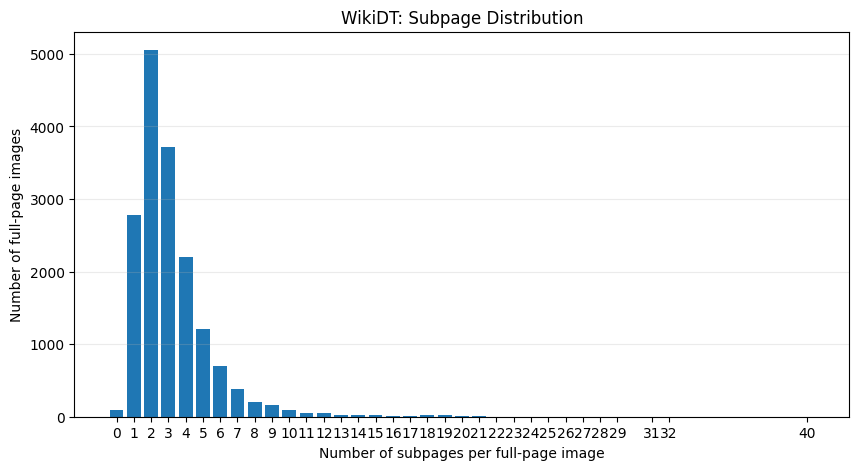

In [12]:
import matplotlib.pyplot as plt

distribution = (
    df_image_mapping["num_subpages"]
    .value_counts()
    .sort_index()
)

display(
    distribution.rename_axis("num_subpages")
    .reset_index(name="num_full_images")
)

plt.figure(figsize=(10, 5))

plt.bar(
    distribution.index,
    distribution.values
)

plt.xlabel("Number of subpages per full-page image")
plt.ylabel("Number of full-page images")
plt.title("WikiDT: Subpage Distribution")
plt.xticks(distribution.index)
plt.grid(axis="y", alpha=0.25)

plt.show()

In [13]:
df_image_mapping.to_csv(
    RESULTS_DIR / "full_image_subpage_mapping.csv",
    index=False
)

df_no_subpages.to_csv(
    RESULTS_DIR / "images_without_subpages.csv",
    index=False
)

df_orphan_subpages.to_csv(
    RESULTS_DIR / "orphan_subpages.csv",
    index=False
)

df_invalid_names.to_csv(
    RESULTS_DIR / "invalid_subpage_names.csv",
    index=False
)

print("EDA reports saved to:", RESULTS_DIR)

EDA reports saved to: /content/drive/MyDrive/WikiDT_Persistent/results


In [14]:
summary = pd.DataFrame({
    "Metric": [
        "Total full-page images",
        "Total subpage images",
        "Full images with no subpages",
        "Subpages with missing parent images",
        "Subpages with invalid filenames",
        "Full images with at least one subpage"
    ],
    "Count": [
        len(df_full_images),
        len(df_sub_images),
        len(df_no_subpages),
        len(df_orphan_subpages),
        len(df_invalid_names),
        (df_image_mapping["num_subpages"] > 0).sum()
    ]
})

display(summary)

print("\nSubpage count distribution:")
display(
    df_image_mapping["num_subpages"]
    .value_counts()
    .sort_index()
    .rename_axis("num_subpages")
    .reset_index(name="num_full_images")
)

,Metric,Count
0,Total full-page images,16887
1,Total subpage images,54032
2,Full images with no subpages,93
3,Subpages with missing parent images,0
4,Subpages with invalid filenames,0
5,Full images with at least one subpage,16794



Subpage count distribution:


,num_subpages,num_full_images
0,0,93
1,1,2785
2,2,5053
3,3,3717
4,4,2200
5,5,1212
6,6,693
7,7,388
8,8,209
9,9,165


In [15]:
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import xml.etree.ElementTree as ET
import pandas as pd
import numpy as np
import random
import re

# Locate detection annotation directories
detection_dir = DETECTION_DIR

print("Detection directory:", detection_dir)

for split in ["train", "val", "test"]:
    folder = detection_dir / split
    xml_files = list(folder.rglob("*.xml")) if folder.exists() else []

    print(f"{split}: {len(xml_files)} XML files")

# Build XML lookup by image stem
xml_lookup = {}

for split in ["train", "val", "test"]:
    folder = detection_dir / split

    if folder.exists():
        for xml_path in folder.rglob("*.xml"):
            xml_lookup.setdefault(xml_path.stem, []).append(xml_path)

print("\nUnique annotated image stems:", len(xml_lookup))
print("Example annotation:", next(iter(xml_lookup.items()), None))

Detection directory: /content/drive/MyDrive/WikiDT_Persistent/data/detection
train: 43248 XML files
val: 5374 XML files
test: 5410 XML files

Unique annotated image stems: 54032
Example annotation: ('28137918_page_seg_1', [PosixPath('/content/drive/MyDrive/WikiDT_Persistent/data/detection/train/28137918_page_seg_1.xml')])


In [16]:
def get_table_boxes(subpage_name):
    """
    Return table bounding boxes for a subpage.

    Output:
    [
      {
        'label': 'table',
        'xmin': ...,
        'ymin': ...,
        'xmax': ...,
        'ymax': ...
      }
    ]
    """

    stem = Path(subpage_name).stem
    xml_paths = xml_lookup.get(stem, [])

    if not xml_paths:
        return [], None

    # Normally one XML per image
    xml_path = xml_paths[0]

    root = ET.parse(xml_path).getroot()

    boxes = []

    for obj in root.findall(".//object"):
        label = obj.findtext("name", default="unknown")
        bbox = obj.find("bndbox")

        if bbox is None:
            continue

        try:
            xmin = float(bbox.findtext("xmin"))
            ymin = float(bbox.findtext("ymin"))
            xmax = float(bbox.findtext("xmax"))
            ymax = float(bbox.findtext("ymax"))
        except (TypeError, ValueError):
            continue

        boxes.append({
            "label": label,
            "xmin": xmin,
            "ymin": ymin,
            "xmax": xmax,
            "ymax": ymax
        })

    return boxes, xml_path

In [17]:
from IPython.display import display, Markdown

# Fast lookup: subpage name -> actual file path
subpage_path_lookup = {
    p.name: p for p in sub_images
}

fullpage_path_lookup = {
    p.name: p for p in full_images
}

def show_random_wikidt_page():
    # Select a random full image with at least one subpage
    candidates = [
        name for name in fullpage_path_lookup
        if name in set(df_sub_images["parent_image"])
    ]

    selected = random.choice(candidates)

    full_path = fullpage_path_lookup[selected]

    page_subpages = (
        df_sub_images[
            df_sub_images["parent_image"] == selected
        ]["subpage_name"]
        .tolist()
    )

    # Sort by segment number
    page_subpages.sort(
        key=lambda x: int(
            re.search(r"_seg_(\d+)\.png$", x).group(1)
        )
    )

    display(Markdown(f"## Random WikiDT page: `{selected}`"))

    # 1. Full-page screenshot
    with Image.open(full_path) as img:
        full_img = img.copy()

    print("Full-page dimensions:", full_img.size)
    print("Number of subpages:", len(page_subpages))

    plt.figure(figsize=(12, 14))
    plt.imshow(full_img)
    plt.title(f"Full-page screenshot: {selected}")
    plt.axis("off")
    plt.show()

    # 2. Subpages with table annotations
    all_boxes = []

    for subpage_name in page_subpages:
        sub_path = subpage_path_lookup.get(subpage_name)

        if sub_path is None:
            print("Missing subpage:", subpage_name)
            continue

        with Image.open(sub_path) as img:
            sub_img = img.copy()

        boxes, xml_path = get_table_boxes(subpage_name)

        fig, ax = plt.subplots(figsize=(12, 9))
        ax.imshow(sub_img)

        for i, box in enumerate(boxes):
            x = box["xmin"]
            y = box["ymin"]
            w = box["xmax"] - x
            h = box["ymax"] - y

            rect = patches.Rectangle(
                (x, y), w, h,
                linewidth=2,
                edgecolor="red",
                facecolor="none"
            )
            ax.add_patch(rect)

            ax.text(
                x, max(0, y - 5),
                f'{box["label"]} #{i+1}',
                color="white",
                fontsize=10,
                bbox=dict(
                    facecolor="red",
                    alpha=0.8,
                    pad=2
                )
            )

            all_boxes.append({
                "full_image": selected,
                "subpage": subpage_name,
                "table_number": i + 1,
                **box
            })

        ax.set_title(
            f"{subpage_name} | "
            f"{sub_img.width}x{sub_img.height} | "
            f"{len(boxes)} annotated objects"
        )

        ax.axis("off")
        plt.tight_layout()
        plt.show()

        if xml_path is None:
            print("No XML annotation found for:", subpage_name)

    # 3. Coordinate summary
    if all_boxes:
        df_boxes = pd.DataFrame(all_boxes)

        display(Markdown("### Table bounding-box coordinates"))
        display(df_boxes)
    else:
        print("No table bounding boxes found for this page.")

    return selected

## Random WikiDT page: `1621212_page.png`

Full-page dimensions: (1600, 7323)
Number of subpages: 3


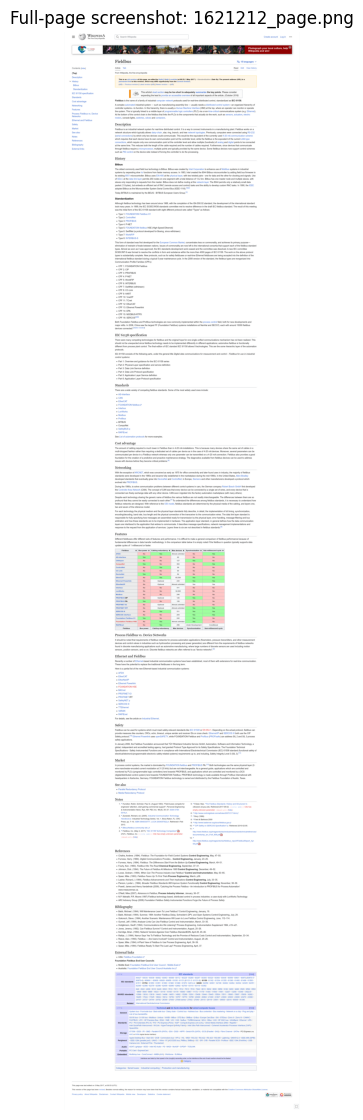

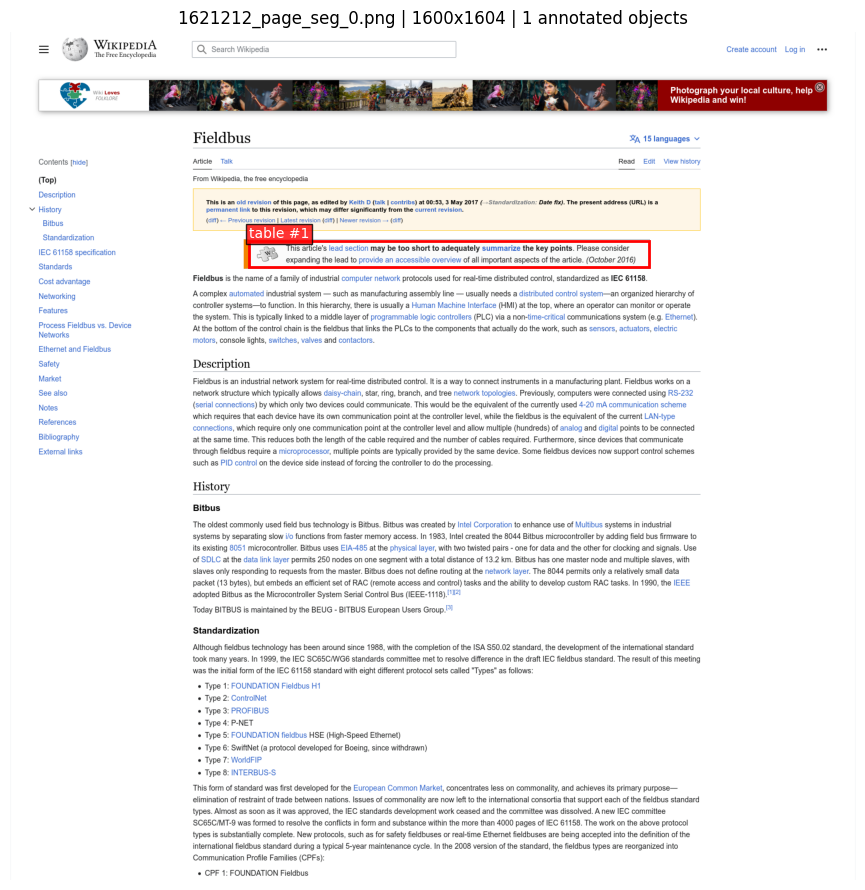

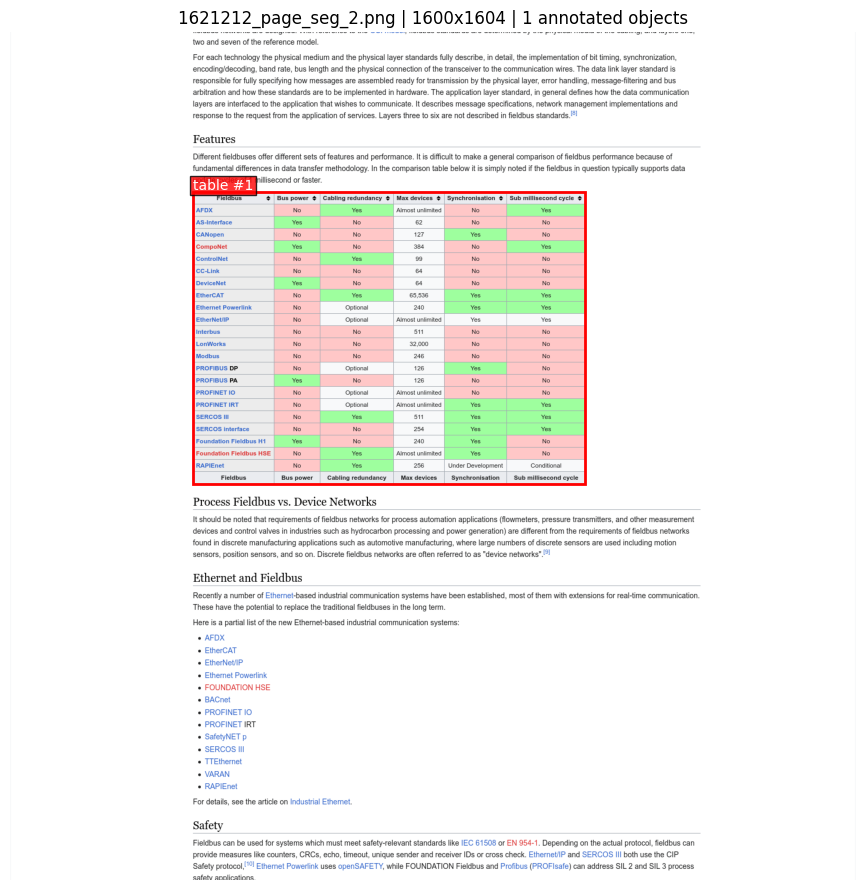

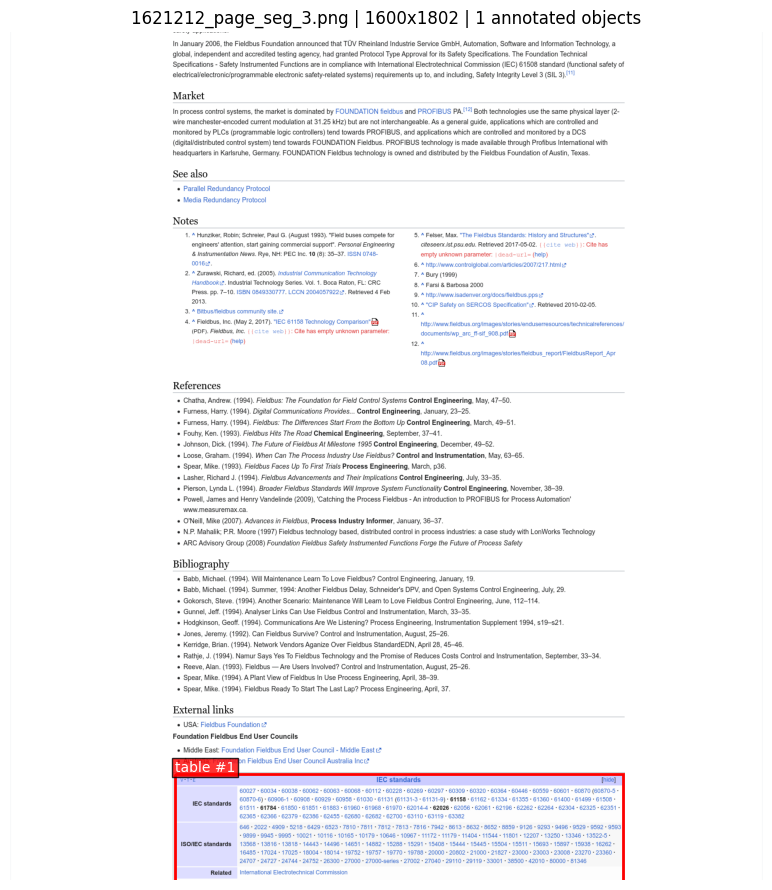

### Table bounding-box coordinates

,full_image,subpage,table_number,label,xmin,ymin,xmax,ymax
0,1621212_page.png,1621212_page_seg_0.png,1,table,452.0,394.0,1209.0,444.0
1,1621212_page.png,1621212_page_seg_2.png,1,table,346.0,302.0,1088.0,854.0
2,1621212_page.png,1621212_page_seg_3.png,1,table,350.0,1576.0,1302.0,2190.0


In [18]:
selected_page = show_random_wikidt_page()

In [21]:

from pathlib import Path
from collections import defaultdict
import xml.etree.ElementTree as ET
import pandas as pd
from tqdm.auto import tqdm
import time

start = time.time()
PRINT_EVERY = 2000

# Locate detection directory
detection_dir = Path(
    df_sub_images.iloc[0]["subpage_path"]
).parent.parent

print(f"Full-page images: {len(df_full_images):,}")
print(f"Subpage images:   {len(df_sub_images):,}")
print(f"Detection directory: {detection_dir}")

# Find XML annotations once
xml_files = []
for split in ["train", "val", "test"]:
    files = list((detection_dir / split).rglob("*.xml"))
    xml_files.extend(files)
    print(f"{split}: {len(files):,} XML files")

print(f"Total XML files: {len(xml_files):,}\n", flush=True)

# Map subpage stem to parent full-page image
subpage_lookup = {
    Path(name).stem: parent
    for name, parent in zip(
        df_sub_images["subpage_name"],
        df_sub_images["parent_image"]
    )
    if pd.notna(parent)
}

page_table_counts = defaultdict(int)
page_annotated_subpages = defaultdict(set)

processed = 0
matched = 0
subpages_with_tables = 0
total_tables = 0
invalid_xml = 0

# Scan annotations
for xml_path in tqdm(xml_files, desc="Scanning XML"):
    processed += 1
    parent = subpage_lookup.get(xml_path.stem)

    if parent is not None:
        try:
            root = ET.parse(xml_path).getroot()

            num_tables = sum(
                1 for obj in root.findall(".//object")
                if (obj.findtext("name") or "").strip().lower() == "table"
            )

            matched += 1
            page_annotated_subpages[parent].add(xml_path.stem)
            page_table_counts[parent] += num_tables
            total_tables += num_tables

            if num_tables > 0:
                subpages_with_tables += 1

        except ET.ParseError:
            invalid_xml += 1

    if processed % PRINT_EVERY == 0:
        full_pages_with_tables = sum(
            n > 0 for n in page_table_counts.values()
        )
        print(
            f"Processed {processed:,}/{len(xml_files):,} | "
            f"Matched: {matched:,} | "
            f"Subpages with tables: {subpages_with_tables:,} | "
            f"Tables: {total_tables:,} | "
            f"Full pages with tables: {full_pages_with_tables:,} | "
            f"Elapsed: {(time.time()-start)/60:.1f} min",
            flush=True
        )

# Update full-page DataFrame
df_image_mapping["num_tables"] = (
    df_image_mapping["image_name"]
    .map(page_table_counts)
    .fillna(0)
    .astype(int)
)

annotated_counts = {
    page: len(stems)
    for page, stems in page_annotated_subpages.items()
}

df_image_mapping["num_annotated_subpages"] = (
    df_image_mapping["image_name"]
    .map(annotated_counts)
    .fillna(0)
    .astype(int)
)

# Final summary
print("\n========== FINAL SUMMARY ==========")
print(f"Full-page images:       {len(df_full_images):,}")
print(f"Subpage images:         {len(df_sub_images):,}")
print(f"XML files processed:    {processed:,}")
print(f"Matched XML files:      {matched:,}")
print(f"Subpages with tables:   {subpages_with_tables:,}")
print(f"Total tables found:     {total_tables:,}")
print(f"Full pages with tables: {(df_image_mapping['num_tables'] > 0).sum():,}")
print(f"Invalid XML files:      {invalid_xml:,}")
print(f"Elapsed:                {(time.time()-start)/60:.2f} minutes")

display(
    df_image_mapping[
        ["image_name", "num_subpages",
         "num_annotated_subpages", "num_tables"]
    ].head(10)
)


Full-page images: 16,887
Subpage images:   54,032
Detection directory: /content/drive/MyDrive/WikiDT_Persistent/data/detection
train: 43,248 XML files
val: 5,374 XML files
test: 5,410 XML files
Total XML files: 54,032



Scanning XML:   0%|          | 0/54032 [00:00<?, ?it/s]

Processed 2,000/54,032 | Matched: 2,000 | Subpages with tables: 2,000 | Tables: 8,329 | Full pages with tables: 659 | Elapsed: 11.1 min
Processed 4,000/54,032 | Matched: 4,000 | Subpages with tables: 4,000 | Tables: 15,165 | Full pages with tables: 1,280 | Elapsed: 11.2 min
Processed 6,000/54,032 | Matched: 6,000 | Subpages with tables: 6,000 | Tables: 22,019 | Full pages with tables: 1,963 | Elapsed: 11.3 min
Processed 8,000/54,032 | Matched: 8,000 | Subpages with tables: 8,000 | Tables: 28,953 | Full pages with tables: 2,891 | Elapsed: 11.3 min
Processed 10,000/54,032 | Matched: 10,000 | Subpages with tables: 10,000 | Tables: 34,821 | Full pages with tables: 3,788 | Elapsed: 11.4 min
Processed 12,000/54,032 | Matched: 12,000 | Subpages with tables: 12,000 | Tables: 40,809 | Full pages with tables: 4,502 | Elapsed: 11.4 min
Processed 14,000/54,032 | Matched: 14,000 | Subpages with tables: 14,000 | Tables: 47,625 | Full pages with tables: 5,314 | Elapsed: 11.5 min
Processed 16,000/54,0

,image_name,num_subpages,num_annotated_subpages,num_tables
0,10006830_page.png,2,2,3
1,10007452_page.png,2,2,6
2,10015132_page.png,5,5,25
3,10015518_page.png,3,3,12
4,10017154_page.png,10,10,36
5,10017434_page.png,4,4,16
6,10020178_page.png,1,1,1
7,10021158_page.png,2,2,5
8,10022075_page.png,1,1,2
9,10023387_page.png,2,2,5


In [22]:
def classify_image(row):
    if row["num_subpages"] == 0:
        return "no_subpages"

    if row["num_tables"] > 0:
        return "usable_table_image"

    if row["num_annotated_subpages"] == 0:
        return "missing_annotations"

    return "no_annotated_tables"

df_image_mapping["eda_status"] = (
    df_image_mapping.apply(classify_image, axis=1)
)

display(
    df_image_mapping["eda_status"]
    .value_counts()
    .rename_axis("status")
    .reset_index(name="count")
)

,status,count
0,usable_table_image,16794
1,no_subpages,93


In [23]:
# Primary dataset for table-focused image embeddings
df_primary = df_image_mapping[
    df_image_mapping["eda_status"] == "usable_table_image"
].copy()

# Other images retained for review
df_review = df_image_mapping[
    df_image_mapping["eda_status"] != "usable_table_image"
].copy()

print("Primary dataset:", len(df_primary))
print("Review dataset:", len(df_review))

df_primary.to_csv(
    RESULTS_DIR / "primary_table_image_dataset.csv",
    index=False
)

df_review.to_csv(
    RESULTS_DIR / "images_for_review.csv",
    index=False
)

Primary dataset: 16794
Review dataset: 93


## 5. Reuse in future training notebooks

Mount Drive, then point your PyTorch Dataset at these persistent paths. For faster GPU training, optionally copy a **filtered subset** from Drive to `/content/` at the start of each runtime; this is a local copy, not a Hugging Face download. Avoid repeatedly reading thousands of small images directly from mounted Drive during each epoch.

```python
from google.colab import drive
drive.mount('/content/drive')
from pathlib import Path
ROOT = Path('/content/drive/MyDrive/WikiDT_Persistent/data')
FULL_IMAGE_DIR = ROOT / 'images'
SUB_IMAGE_DIR = ROOT / 'detection' / 'images'
```

**Note:** Training a ViT image encoder does not automatically provide image–text pairs.